# IMDb Rating Regression

Mục tiêu: ước lượng `imdb_rating` bằng Linear Regression và Decision Tree Regressor, sử dụng cùng một tập train/test và so sánh bằng MSE, RMSE, R².

**Diễn giải phạm vi:** `metascore` được đưa vào làm predictor. Vì vậy đây là bài toán ước lượng IMDb Rating khi MetaScore và metadata đã biết, không phải dự báo rating trước khi có đánh giá. MetaScore có thể mang tín hiệu tương quan mạnh với target; kết quả không chứng minh quan hệ nhân quả.

Toàn bộ tiền xử lý được đặt trong pipeline và chỉ fit trên train. Notebook chỉ đọc `data/processed/imdb_cleaned.csv`; bảng và hình được hiển thị inline, không ghi artifact ra ngoài.

## 1. Nạp thư viện và tìm dữ liệu

Tìm project root từ thư mục hiện hành hoặc các thư mục cha để notebook không phụ thuộc đường dẫn máy cá nhân.

In [6]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

DATA_RELATIVE_PATH = Path("data") / "processed" / "imdb_cleaned.csv"
project_root = next(
    (candidate for candidate in (Path.cwd(), *Path.cwd().parents)
     if (candidate / DATA_RELATIVE_PATH).is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError(
        f"Không tìm thấy {DATA_RELATIVE_PATH} từ thư mục hiện tại "
        f"({Path.cwd()}) hoặc các thư mục cha."
    )

data_path = project_root / DATA_RELATIVE_PATH
df = pd.read_csv(data_path)
print(f"Dữ liệu: {data_path.relative_to(project_root)}")
print(f"Kích thước ban đầu: {df.shape[0]:,} dòng × {df.shape[1]} cột")
display(df.head())

Dữ liệu: data\processed\imdb_cleaned.csv
Kích thước ban đầu: 3,716 dòng × 20 cột


,title,imdb_rating,year,duration_minutes,metascore,certificates,director,star_cast,source_file,poster_url,genres,imdb_id,imdb_rating_missing,year_missing,duration_minutes_missing,metascore_missing,director_missing,star_cast_missing,certificates_missing,genres_missing
0,End of the Spear,6.8,2005,108.0,45.0,PG-13,Jim Hanon,Louie LeonardoChad AllenJack Guzman,IMDb_Dataset_2.csv,https://m.media-amazon.com/images/M/MV5BMTYxOT...,Adventure,NaN,0,0,0,0,0,0,0,0
1,Elvira Madigan,7.0,1967,91.0,66.0,PG,Bo Widerberg,Pia DegermarkThommy BerggrenLennart Malmer,IMDb_Dataset_2.csv,https://m.media-amazon.com/images/M/MV5BMmY2Nj...,Biography,NaN,0,0,0,0,0,0,0,0
2,The Kid Stays in the Picture,7.3,2002,93.0,75.0,R,Nanette Burstein,Robert EvansEddie AlbertPeter Bart,IMDb_Dataset_2.csv,https://m.media-amazon.com/images/M/MV5BZjhiZm...,Documentary,NaN,0,0,0,0,0,0,0,0
3,It Ain't Over,8.2,2022,99.0,79.0,PG,Sean Mullin,Andy AndresRoger AngellMarty Appel,IMDb_Dataset_2.csv,https://m.media-amazon.com/images/M/MV5BZWViYW...,Documentary,NaN,0,0,0,0,0,0,0,0
4,Mahler,7.0,1974,115.0,66.0,PG,Ken Russell,Robert PowellGeorgina HaleLee Montague,IMDb_Dataset_2.csv,https://m.media-amazon.com/images/M/MV5BYzY4Mz...,Biography,NaN,0,0,0,0,0,0,0,0


## 2. Kiểm tra và chuẩn bị biến

Dùng năm, thời lượng, MetaScore, chứng nhận và thể loại chính. Thể loại chính là nhãn đầu tiên trong danh sách `genres`, theo thứ tự của dữ liệu nguồn. Target phải là số hữu hạn trong miền IMDb 0–10; các feature số không hợp lệ được chuyển thành thiếu để pipeline xử lý.

In [7]:
target_column = "imdb_rating"
numeric_features = ["year", "duration_minutes", "metascore"]
categorical_features = ["certificates", "primary_genre"]
required_columns = [target_column, *numeric_features, "certificates", "genres"]
missing_columns = sorted(set(required_columns).difference(df.columns))
if missing_columns:
    raise ValueError(f"Thiếu các cột bắt buộc trong dữ liệu: {missing_columns}")

prepared = df[required_columns].copy()
prepared[target_column] = pd.to_numeric(prepared[target_column], errors="coerce")
for column in numeric_features:
    prepared[column] = pd.to_numeric(prepared[column], errors="coerce")

genre_text = prepared["genres"].astype("string").str.strip()
prepared["primary_genre"] = genre_text.str.split(",").str[0].str.strip()
prepared["certificates"] = prepared["certificates"].astype("string").str.strip()
prepared["primary_genre"] = prepared["primary_genre"].replace("", pd.NA)
prepared["certificates"] = prepared["certificates"].replace("", pd.NA)

target_valid = (
    prepared[target_column].notna()
    & np.isfinite(prepared[target_column])
    & prepared[target_column].between(0, 10)
)
removed_target_rows = int((~target_valid).sum())
prepared = prepared.loc[target_valid].reset_index(drop=True)
if prepared.empty:
    raise ValueError("Không còn hàng có imdb_rating hợp lệ trong miền 0–10.")

X = prepared[[*numeric_features, *categorical_features]].copy()
y = prepared[target_column].copy()
all_missing_features = [column for column in X if X[column].isna().all()]
if all_missing_features:
    raise ValueError(f"Feature hoàn toàn thiếu, không thể huấn luyện: {all_missing_features}")

print(f"Hàng ban đầu: {len(df):,}")
print(f"Hàng loại do target thiếu/không hợp lệ: {removed_target_rows:,}")
print(f"Hàng dùng cho mô hình: {len(prepared):,}")
print(f"Target range: {y.min():.2f}–{y.max():.2f}; target mean: {y.mean():.2f}")
print("Missing theo feature trước khi chia tập:")
display(X.isna().sum().rename("missing_count").to_frame())
print("Số nhóm thể loại chính:", X["primary_genre"].nunique(dropna=True))
display(X.head())

Hàng ban đầu: 3,716
Hàng loại do target thiếu/không hợp lệ: 0
Hàng dùng cho mô hình: 3,716
Target range: 3.90–9.50; target mean: 6.76
Missing theo feature trước khi chia tập:


,missing_count
year,0
duration_minutes,0
metascore,0
certificates,0
primary_genre,0


Số nhóm thể loại chính: 18


,year,duration_minutes,metascore,certificates,primary_genre
0,2005,108.0,45.0,PG-13,Adventure
1,1967,91.0,66.0,PG,Biography
2,2002,93.0,75.0,R,Documentary
3,2022,99.0,79.0,PG,Documentary
4,1974,115.0,66.0,PG,Biography


## 3. Chia train/test và xây pipeline

Chia 80/20 một lần với `random_state=42`. Median imputation và scaling áp dụng cho feature số; most-frequent imputation và one-hot encoding áp dụng cho feature phân loại. Mỗi transformer chỉ được fit khi pipeline huấn luyện trên train. Scaling có ích cho Linear Regression nhưng không bắt buộc với cây quyết định; dùng cùng cách mã hóa để so sánh đầu vào nhất quán.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]
)
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_features),
        ("categorical", categorical_transformer, categorical_features),
    ]
)

print(f"Train: {len(X_train):,} hàng ({len(X_train) / len(X):.0%})")
print(f"Test:  {len(X_test):,} hàng ({len(X_test) / len(X):.0%})")
print("Hai mô hình sử dụng cùng train/test split và cùng feature đầu vào.")

Train: 2,972 hàng (80%)
Test:  744 hàng (20%)
Hai mô hình sử dụng cùng train/test split và cùng feature đầu vào.


## 4. Huấn luyện hai mô hình baseline

Cấu hình cây được cố định trước khi xem kết quả test (`max_depth=12`, `min_samples_leaf=5`) nhằm giới hạn độ phức tạp. Không tuning trên test set.

In [9]:
models = {
    "Linear Regression": Pipeline(
        steps=[("preprocessing", preprocessor), ("model", LinearRegression())]
    ),
    "Decision Tree": Pipeline(
        steps=[
            ("preprocessing", preprocessor),
            (
                "model",
                DecisionTreeRegressor(
                    random_state=42, max_depth=12, min_samples_leaf=5
                ),
            ),
        ]
    ),
}

predictions = {}
for model_name, model_pipeline in models.items():
    model_pipeline.fit(X_train, y_train)
    predictions[model_name] = model_pipeline.predict(X_test)
    print(f"Đã huấn luyện {model_name}.")

Đã huấn luyện Linear Regression.
Đã huấn luyện Decision Tree.


## 5. Đánh giá trên test set

MSE và RMSE càng thấp càng tốt; R² càng cao càng tốt. R² âm có nghĩa mô hình kém hơn baseline dự đoán trung bình của target trên test set. Các chỉ số này chỉ mô tả phép chia test hiện tại.

In [10]:
metric_rows = []
for model_name, y_pred in predictions.items():
    mse = mean_squared_error(y_test, y_pred)
    metric_rows.append(
        {
            "Model": model_name,
            "MSE": mse,
            "RMSE": np.sqrt(mse),
            "R²": r2_score(y_test, y_pred),
        }
    )

metrics = pd.DataFrame(metric_rows).set_index("Model")
if not np.isfinite(metrics.to_numpy()).all():
    raise ValueError("Có metric không hữu hạn; cần kiểm tra dữ liệu hoặc mô hình.")
display(metrics.round(4))

lower_rmse_model = metrics["RMSE"].idxmin()
higher_r2_model = metrics["R²"].idxmax()
print(f"RMSE thấp nhất: {lower_rmse_model} ({metrics.loc[lower_rmse_model, 'RMSE']:.4f})")
print(f"R² cao nhất: {higher_r2_model} ({metrics.loc[higher_r2_model, 'R²']:.4f})")
if lower_rmse_model != higher_r2_model:
    print("Hai chỉ số xếp hạng khác nhau; cần cân nhắc mục tiêu đánh giá thay vì chọn một mô hình chỉ từ một metric.")

,MSE,RMSE,R²
Model,,,
Linear Regression,0.4810,0.6935,0.3592
Decision Tree,0.5089,0.7133,0.3221


RMSE thấp nhất: Linear Regression (0.6935)
R² cao nhất: Linear Regression (0.3592)


## 6. Actual vs Predicted và residuals

Residual được định nghĩa là `actual - predicted`; residual dương nghĩa mô hình dự đoán thấp hơn thực tế. Đường chéo trong biểu đồ đầu là dự đoán hoàn hảo, đường ngang trong biểu đồ residual là sai số bằng 0.

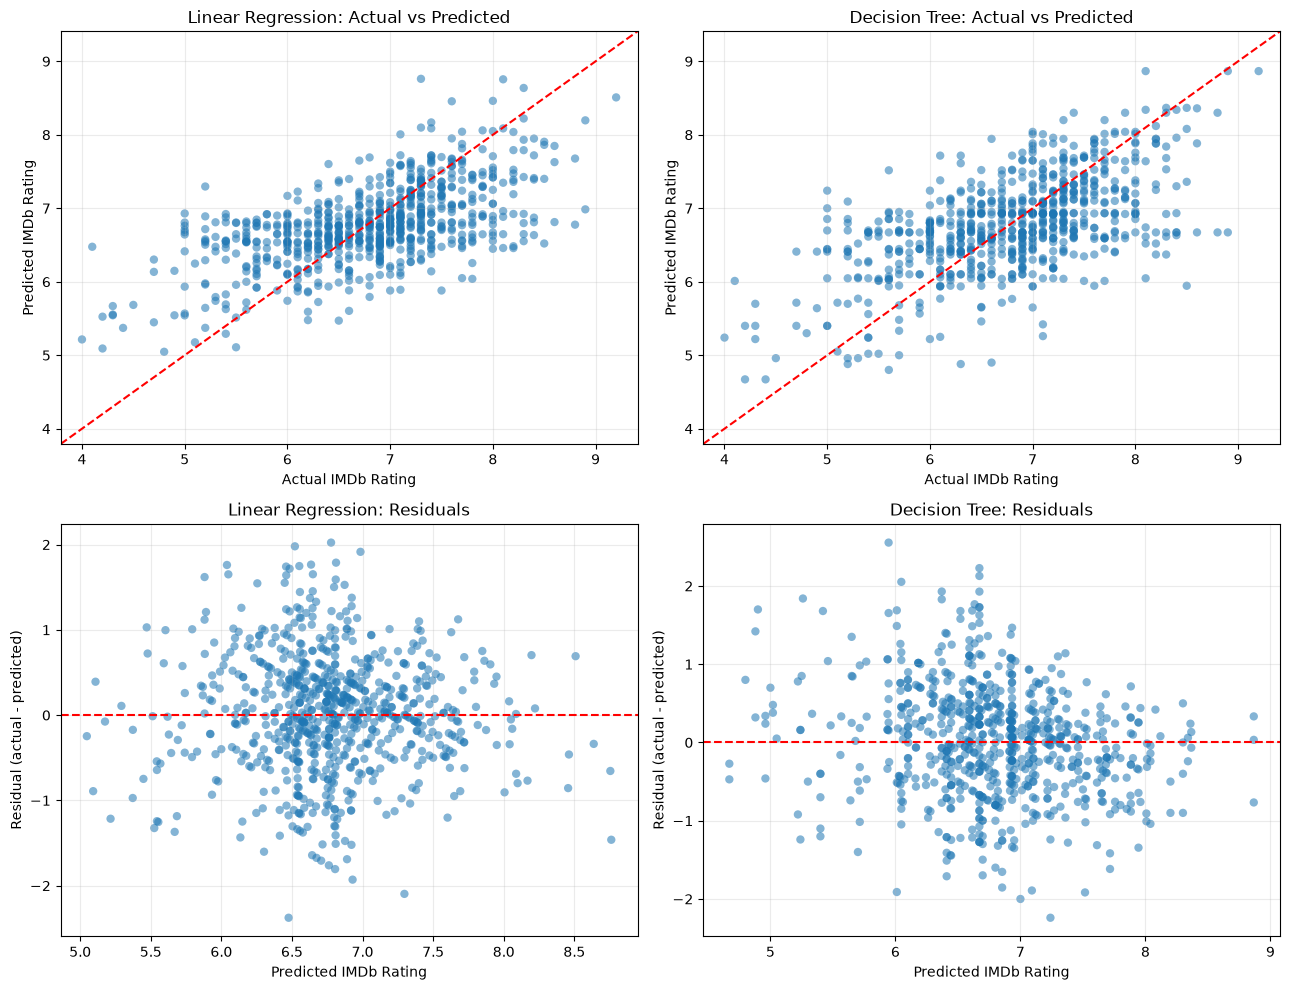

Linear Regression: mean residual=0.0219, median residual=0.0235, residual range=[-2.3762, 2.0231]
Decision Tree: mean residual=0.0113, median residual=0.0333, residual range=[-2.2400, 2.5545]


In [11]:
actual_values = y_test.to_numpy()
plot_min = min(actual_values.min(), *(values.min() for values in predictions.values()))
plot_max = max(actual_values.max(), *(values.max() for values in predictions.values()))
plot_padding = max((plot_max - plot_min) * 0.04, 0.1)
plot_min -= plot_padding
plot_max += plot_padding

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for column, (model_name, y_pred) in enumerate(predictions.items()):
    residuals = actual_values - y_pred
    prediction_axis = axes[0, column]
    prediction_axis.scatter(actual_values, y_pred, alpha=0.55, edgecolors="none")
    prediction_axis.plot([plot_min, plot_max], [plot_min, plot_max], "r--", linewidth=1.5)
    prediction_axis.set(
        title=f"{model_name}: Actual vs Predicted",
        xlabel="Actual IMDb Rating",
        ylabel="Predicted IMDb Rating",
        xlim=(plot_min, plot_max),
        ylim=(plot_min, plot_max),
    )
    prediction_axis.grid(alpha=0.25)

    residual_axis = axes[1, column]
    residual_axis.scatter(y_pred, residuals, alpha=0.55, edgecolors="none")
    residual_axis.axhline(0, color="red", linestyle="--", linewidth=1.5)
    residual_axis.set(
        title=f"{model_name}: Residuals",
        xlabel="Predicted IMDb Rating",
        ylabel="Residual (actual - predicted)",
    )
    residual_axis.grid(alpha=0.25)

fig.tight_layout()
plt.show()

for model_name, y_pred in predictions.items():
    residuals = actual_values - y_pred
    print(
        f"{model_name}: mean residual={residuals.mean():.4f}, "
        f"median residual={np.median(residuals):.4f}, "
        f"residual range=[{residuals.min():.4f}, {residuals.max():.4f}]"
    )

## 7. Nhận xét và giới hạn

So sánh RMSE để nhận biết mô hình có sai số điển hình thấp hơn trên test set và R² để xem mô hình giải thích được bao nhiêu biến thiên tương đối với baseline trung bình. Dùng actual-vs-predicted để quan sát độ lệch so với đường hoàn hảo, và residual plot để tìm bias hoặc mẫu sai số theo mức dự đoán.

Đây là đánh giá trên một phép chia ngẫu nhiên duy nhất, không phải bằng chứng về hiệu năng trên mọi phim hoặc theo thời gian. Đặc biệt, MetaScore đã là một điểm đánh giá liên quan nên làm thay đổi ý nghĩa bài toán; tương quan giữa feature và IMDb Rating không đồng nghĩa quan hệ nhân quả. Chưa dùng test set để lựa chọn/tuning hyperparameter.